# Lost for 66 years: could the 1937 orbit of Hermes have found it again?

**The story.** Karl Reinmuth found a fast-moving asteroid on photographic plates taken at
Heidelberg on 28 October 1937. Two days later it passed about 0.005 au (two lunar distances) from
Earth, a record at the time. Observatories in Germany, South Africa and
the United States caught it on a handful of plates, and then it was gone. With less than a week of
data its orbit was too uncertain to predict, and **1937 UB "Hermes"** became the most famous lost
asteroid. It was found again only on **15 October 2003**, when B. A. Skiff reported a bright
near-Earth-object candidate from the LONEOS survey at Lowell Observatory (station 699). T. B. Spahr
at the Minor Planet Center found earlier single-night detections from the same autumn and
recognised the object as Hermes
([MPEC 2003-T74](https://www.minorplanetcenter.net/mpec/K03/K03T74.html), issued 2003 Oct. 15).
The circular adds that its orbit "has not been linked to the 1937 observations, since when the
object has made almost exactly 31 revolutions". It is now (69230) Hermes, a binary asteroid.

**The question.** The 2003 recovery was a chance rediscovery by a survey, not a targeted search.
Could it have been otherwise? With only the 1937 plates, how well is the orbit known, and where
could Hermes have been on the sky on the night LONEOS found it? We use PyRoOrb's non-linear
uncertainty tools, chiefly the **line of variations (LOV)**: a one-parameter family of orbits
that each fit the data, following the curved valley of good solutions rather than the
straight-line covariance.

1. Fetch the observations and split off the 1937 apparition.
2. Fit 1937 alone. Is the orbit determined? Compare the linear, Monte-Carlo, LOV and
   statistical-ranging (SR) summaries, and check the elements against JPL's orbit at 1937.
3. Carry the 1937 uncertainty to the recovery night with `sample_orbits` and project it onto the
   sky from LONEOS. Where is the true position along the LOV, and how big is the search region?
4. Which Earth encounters between 1937 and 2003 scrambled the prediction?
5. Link the 1937 plates to the modern data, and compare the result with JPL.

In [1]:
import json, time, urllib.parse, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)
T_START = time.time()

PyRoOrb 0.9.1


## 1. The observations

`fetch_observations` returns everything the MPC holds under the number, including the 1937
positions. They were measured on photographic plates at four observatories. The MPC lists them as
running from 25 to 29 October 1937 (UTC); the earliest, from Oak Ridge (801), predates
Reinmuth's discovery plate and was identified later.

In [2]:
obs = pyroorb.fetch_observations("69230")
stations = pyroorb.obscodes()
J1940 = Time("1940-01-01").jd

old = [o for o in obs if o["jd_utc"] < J1940]
print(f"{len(obs)} optical observations in all, {len(obs.meta['radar'])} radar; "
      f"{len(old)} from 1937")
names = {"801": "Oak Ridge (Harvard), USA", "031": "Sonneberg, Germany",
         "078": "Johannesburg (Union Obs.), South Africa", "024": "Heidelberg, Germany"}
df = pd.DataFrame({"UTC": [Time(o["jd_utc"], format="jd").iso[:16] for o in old],
                   "station": [f'{o["obscode"]} {names.get(o["obscode"], "")}' for o in old],
                   "RA (deg)": [round(o["ra_deg"], 4) for o in old],
                   "Dec (deg)": [round(o["dec_deg"], 4) for o in old]})
print(f"1937 arc: {old[-1]['jd_utc'] - old[0]['jd_utc']:.1f} days")
years = sorted({Time(o["jd_utc"], format="jd").datetime.year for o in obs})
print("years with observations:", years[:6], "...", years[-1])
df

2886 optical observations in all, 6 radar; 16 from 1937
1937 arc: 4.7 days
years with observations: [1937, 2000, 2001, 2002, 2003, 2005] ... 2026


,UTC,station,RA (deg),Dec (deg)
0,1937-10-25 05:14,"801 Oak Ridge (Harvard), USA",34.1662,5.9700
1,1937-10-26 22:03,"031 Sonneberg, Germany",32.0780,6.5115
2,1937-10-26 22:36,"031 Sonneberg, Germany",32.0406,6.5226
3,1937-10-27 21:11,"078 Johannesburg (Union Obs.), South Africa",29.7794,7.2174
4,1937-10-27 21:26,"078 Johannesburg (Union Obs.), South Africa",29.7427,7.2261
5,1937-10-27 21:41,"078 Johannesburg (Union Obs.), South Africa",29.7060,7.2347
6,1937-10-27 21:43,"078 Johannesburg (Union Obs.), South Africa",29.6985,7.2371
7,1937-10-27 21:58,"078 Johannesburg (Union Obs.), South Africa",29.6605,7.2461
8,1937-10-27 22:13,"078 Johannesburg (Union Obs.), South Africa",29.6227,7.2547
9,1937-10-27 23:57,"031 Sonneberg, Germany",29.3678,7.2130


After 1937 the next observations are from 2000-2002, all precoveries found after the recovery
(ESO La Silla, Siding Spring, LONEOS, NEAT). In 2003 LINEAR (704) caught it on single nights from
26 August, LONEOS itself on 28 September, NEAT (608) on 5 October; each was reported as a
probable main-belt object. The recovery tracklet, four LONEOS positions on 15 October 2003, is the
one we will try to predict.

In [3]:
recovery = sorted((o for o in obs if o["obscode"] == "699"
                   and Time(o["jd_utc"], format="jd").iso[:10] == "2003-10-15"),
                  key=lambda o: o["jd_utc"])
REC = recovery[0]
print(f"LONEOS recovery: {len(recovery)} positions, first at "
      f"{Time(REC['jd_utc'], format='jd').iso[:19]} UTC, RA {REC['ra_deg']:.4f}, "
      f"Dec {REC['dec_deg']:+.4f}, reported mag {REC['mag']}")

LONEOS recovery: 4 positions, first at 2003-10-15 07:23:06 UTC, RA 26.3711, Dec +2.7543, reported mag 14.4

## 2. The 1937 orbit on its own

### 2a. With the default weights: one night survives

Observations made before 1993 carry no uncertainty of their own, so PyRoOrb weights them at 3"
(the find_orb convention for old photographic astrometry). We fit the 16 positions as they come.

In [4]:
def show_fit(f, label):
    kept = [r["obscode"] for r in f.residuals() if r["included"]]
    el = f.elements()
    print(f"{label}: {f.n_observations()} of {f.n_total_observations()} observations kept "
          f"(stations {sorted(set(kept))}), rms {f.rms_residual():.1f}\", "
          f"determined: {f.is_determined}")
    print(f"   a = {el['a']:.3f} au, e = {el['e']:.3f}, i = {el['i']:.2f} deg")

meta1937 = dict(obs.meta, radar=[])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", pyroorb.UndeterminedOrbitWarning)
    fit_default = pyroorb.fit_orbit(pyroorb.Observations(old, meta1937), designation="69230")
show_fit(fit_default, "default 3\" weights")
print(fit_default.determinacy()["headline"])

default 3" weights: 6 of 16 observations kept (stations ['078']), rms 2.2", determined: False
   a = 1.196 au, e = 0.353, i = 2.17 deg
Essentially unconstrained — 0.0-day, 1-opposition arc


The fit has kept only the six Johannesburg positions from one night and rejected everything
else, so it reports an undetermined orbit. The cause is the weights. These are 1937 plates of an
object moving up to 1.4 arcminutes per minute, and the four stations disagree with one another
at the level of tens of arcseconds. At 3" each station's night looks like an outlier against
the others, and the rejection keeps the most self-consistent night.

### 2b. Weighting the plates for what they are

We give every 1937 position the same uncertainty, 30". The value is set by the data, not by the
answer: the fit below has an rms of about 25" per axis, so 30" is about the scatter the plates
show among themselves. At 10" three Sonneberg positions are still rejected; at 30" and at 60" all
16 are kept and the elements are the same (only their σ scales).

In [5]:
SIGMA_1937 = 30.0      # arcsec, about the plates' own scatter (rms ~25" per axis)
old_w = [dict(o, sigma_ra=SIGMA_1937, sigma_dec=SIGMA_1937) for o in old]
fit37 = pyroorb.fit_orbit(pyroorb.Observations(old_w, meta1937), designation="69230")
show_fit(fit37, f"1937 at {SIGMA_1937:.0f}\"")
print("epoch", fit37.epoch_iso()[:19], "TDB, U =", round(fit37.uncertainty_parameter(), 1))
for S in (10.0, 60.0):                                 # how much does the choice matter?
    show_fit(pyroorb.fit_orbit(pyroorb.Observations(
        [dict(o, sigma_ra=S, sigma_dec=S) for o in old], meta1937), designation="69230"),
        f"1937 at {S:.0f}\"")
res = pd.DataFrame(fit37.residuals())[["obscode", "d_ra_arcsec", "d_dec_arcsec"]].round(1)
res.T

1937 at 30": 16 of 16 observations kept (stations ['024', '031', '078', '801']), rms 24.7", determined: True
   a = 1.633 au, e = 0.622, i = 6.20 deg
epoch 1937-10-25 05:14:36 TDB, U = 10.8
1937 at 10": 13 of 16 observations kept (stations ['024', '031', '078', '801']), rms 9.0", determined: True
   a = 1.587 au, e = 0.608, i = 6.06 deg


1937 at 60": 16 of 16 observations kept (stations ['024', '031', '078', '801']), rms 24.7", determined: True
   a = 1.633 au, e = 0.622, i = 6.20 deg


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
obscode,801,031,031,078,078,078,078,078,078,031,031,024,031,024,031,031
d_ra_arcsec,-6.9,-22.9,15.2,-12.3,-7.6,-1.8,-10.1,-7.8,-4.0,-22.1,93.6,-4.3,-55.0,-11.5,65.0,-1.3
d_dec_arcsec,0.0,-17.3,-17.6,5.6,4.1,2.5,7.0,6.5,4.8,-8.2,-11.4,15.8,4.7,12.7,4.7,-13.7


All 16 positions are kept and the orbit is **determined**. The range profile shows why. It holds
the distance at the arc's first *included* observation fixed and refits the rest. Hermes was only
0.06 au away, so the four stations, spread over two hemispheres and three continents, saw it from
very different directions. That parallax pins the distance, which a single night from one station
cannot do. The two profiles are anchored at different moments (the one-night fit at its first
Johannesburg position, two days later and closer), so each has its own dotted line: JPL's
geocentric distance at that moment, from Horizons.

default weights (one night kept): distances 0.0006-0.3458 au fit, best 0.0084; JPL 0.0303 au


all 16 plates at 30": distances 0.0536-0.0696 au fit, best 0.0582; JPL 0.0583 au


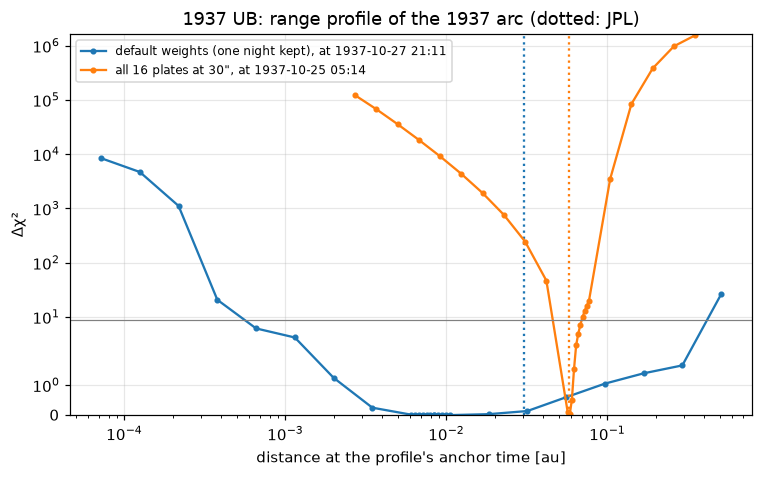

In [6]:
def horizons(params):
    q = urllib.parse.urlencode({"format": "json", "COMMAND": "'DES=1937 UB;'", **params})
    return json.load(urllib.request.urlopen("https://ssd.jpl.nasa.gov/api/horizons.api?" + q,
                                            timeout=60))["result"]

fig, ax = plt.subplots()
for n, (f, label) in enumerate(((fit_default, "default weights (one night kept)"),
                                (fit37, f"all 16 plates at {SIGMA_1937:.0f}\""))):
    prof = f.range_profile()
    rho = np.array([r["rho"] for r in prof["rows"]]); chi2 = np.array([r["chi2"] for r in prof["rows"]])
    t_utc = Time(prof["t0_tdb"], format="jd", scale="tdb").utc
    ax.plot(rho, chi2 - chi2.min(), marker=".", c=f"C{n}", label=f"{label}, at {t_utc.iso[:16]}")
    v = f.range_verdict()
    msg = f"{label}: distances {v['rho_lo']:.4f}-{v['rho_hi']:.4f} au fit, best {v['rho_best']:.4f}"
    try:
        row = horizons({"EPHEM_TYPE": "OBSERVER", "CENTER": "'500@399'", "TLIST": f"'{t_utc.jd}'",
                        "QUANTITIES": "'20'", "CSV_FORMAT": "YES"}).split("$$SOE")[1].split("$$EOE")[0].split(",")
        ax.axvline(float(row[3]), ls=":", c=f"C{n}")
        msg += f"; JPL {float(row[3]):.4f} au"
    except Exception as ex:
        msg += f" (Horizons unavailable: {ex})"
    print(msg)
ax.axhline(9, c="grey", lw=0.8)
ax.set(xscale="log", yscale="symlog", ylim=(0, None), xlabel="distance at the profile's anchor time [au]",
       ylabel="Δχ²", title="1937 UB: range profile of the 1937 arc (dotted: JPL)")
ax.legend(fontsize=8); plt.show()

### 2c. Four views of the same uncertainty

PyRoOrb has several ways to describe an orbit's uncertainty:

* **linear**: the covariance's σ, the tangent to the valley of solutions at the best fit;
* **Monte Carlo** (`monte_carlo_uncertainty`, `element_ranges`): clones drawn from that
  covariance, converted to elements;
* **LOV** (`lov_uncertainty`): orbits stepped along the weakest direction and *re-fitted* at each
  step, so they follow the valley if it curves;
* **statistical ranging** (`sr_uncertainty`): random two-body orbits through the first and last
  lines of sight, kept when they fit. It is a single-night tool.

Each orbit is compared with JPL's current orbit (which uses the 1937 plates and 89 years of later
data), read from Horizons as osculating elements at the same 1937 epoch.

In [7]:
lin, mc, rng = fit37.element_sigmas(), fit37.monte_carlo_uncertainty()["sigmas"], fit37.element_ranges()
N_LOV = 2401
lov = fit37.lov_uncertainty(n_steps=N_LOV, n_sigma=3.0)
sr = fit37.sr_uncertainty()
print("statistical ranging:", "no family (a 5-night, 4-station arc is outside SR's single-night regime)"
      if sr is None else sr)

jpl37 = {}
try:
    row = horizons({"EPHEM_TYPE": "ELEMENTS", "CENTER": "'500@10'", "REF_PLANE": "ECLIPTIC",
                    "TLIST": f"'{fit37.epoch_jd()}'", "TIME_TYPE": "TDB", "OUT_UNITS": "AU-D",
                    "CSV_FORMAT": "YES"}).split("$$SOE")[1].split("$$EOE")[0].split(",")
    jpl37 = dict(zip(["e", "q", "i", "asc_node", "arg_per", "Tp", "n", "M", "nu", "a"],
                     map(float, row[2:12])))
except Exception as ex:
    print("Horizons unavailable:", ex)

rows = []
for k in ("a", "e", "q", "i", "asc_node", "arg_per", "M", "P"):
    v = fit37.elements()[k]
    rows.append({"element": k, "PyRoOrb 1937-only": round(v, 4),
                 "linear σ": f"{lin[k]:.3g}", "Monte-Carlo σ": f"{mc[k][1]:.3g}",
                 "LOV σ": f"{lov['sigmas'][k][1]:.3g}",
                 "MC 5-95 %": f"{rng[k][0]:.3f} – {rng[k][1]:.3f}",
                 "JPL at 1937 epoch": round(jpl37[k], 4) if k in jpl37 else
                     (round(2 * np.pi / np.radians(jpl37["n"]) / 365.25, 4) if k == "P" and jpl37 else None)})
tab = pd.DataFrame(rows).set_index("element")
tab["(PyRoOrb-JPL)/σ"] = [round((tab.loc[k, "PyRoOrb 1937-only"] - tab.loc[k, "JPL at 1937 epoch"])
                                / float(tab.loc[k, "linear σ"]), 2) if jpl37 else None for k in tab.index]
tab

statistical ranging: no family (a 5-night, 4-station arc is outside SR's single-night regime)


,PyRoOrb 1937-only,linear σ,Monte-Carlo σ,LOV σ,MC 5-95 %,JPL at 1937 epoch,(PyRoOrb-JPL)/σ
element,,,,,,,
a,1.6332,0.116,0.121,0.119,1.469 – 1.866,1.6350,-0.02
e,0.6218,0.0347,0.0349,0.0347,0.564 – 0.680,0.6224,-0.02
q,0.6176,0.0129,0.013,0.0129,0.597 – 0.640,0.6174,0.02
i,6.2030,0.357,0.359,0.357,5.609 – 6.801,6.2081,-0.01
asc_node,35.9872,0.008,0.00798,0.00795,35.973 – 36.000,35.9862,0.13
arg_per,90.7413,0.02,0.0197,0.00351,90.705 – 90.769,90.7355,0.29
M,334.1294,3.35,3.37,3.35,328.458 – 339.612,334.1822,-0.02
P,2.0872,0.222,0.235,0.23,1.780 – 2.549,2.0907,-0.02


**Reading the table.** The five-day 1937 arc gives an orbit that agrees with JPL's within 0.3σ
in every element, and within 0.02σ in most. The angles that fix the orbit's orientation (node and argument
of perihelion) are known to 0.01°, and the perihelion distance *q* to 2 %. The weak elements are
the size *a*, the period *P* and the mean anomaly *M* (where on the orbit the object is): *P* is
2.09 ± 0.23 years. The linear, Monte-Carlo and LOV σ agree closely, so in 1937 the valley of
solutions is still nearly straight. (The LOV σ of the argument of perihelion is smaller because
the LOV measures the spread along the one weak direction only, and ω barely moves along it.) SR finds no family: on a multi-night, multi-station arc the
orbits that fit are too thin a sliver for its random trials. That is expected, and
`sample_orbits` says to use the LOV or the covariance there.

Note that JPL's *osculating* *a* in 1937 is 1.635 au, not the 1.655 au of today's catalogues:
the 1937 and 1942 Earth encounters changed it (section 4).

## 3. Carrying the 1937 orbit to the night of the recovery

A period known to ±0.23 years, carried over 66 years (about 31 orbits), means the object's
position along its orbit in 2003 is uncertain by about ±31 × 0.23 / 2.09 ≈ **±3.5 revolutions**.
The uncertainty no longer has an ellipse shape; it wraps around the orbit several times. We
follow it with two ensembles:

* **LOV**: 2401 re-fitted orbits along the line of variations, ±3σ at equal-probability steps
  (each carries equal weight; this many, so that consecutive members are only about a degree
  apart along the orbit);
* **covariance**: 1500 clones drawn from the 1937 covariance.

Each is projected onto the sky from LONEOS at the time of the first recovery observation
(`OrbitEnsemble.sky_positions`). For the LOV we also count the revolutions each member makes
between 1937 and 2003, by following its heliocentric longitude every 20 days.

In [8]:
t0 = time.time()
ens_lov = pyroorb.sample_orbits(fit37, N_LOV, method="lov", n_sigma=3.0)
k_lov = np.asarray(lov["k"])                        # each member's offset along the LOV, in σ
sky_lov = ens_lov.sky_positions([REC["jd_utc"]], site="699")
grid = np.arange(fit37.epoch_jd(), REC["jd_utc"], 20.0)
path = ens_lov.propagate(grid)                      # (n_times, members, 6), heliocentric
lon = np.unwrap(np.arctan2(path[:, :, 1], path[:, :, 0]), axis=0)
n_rev = (lon[-1] - lon[0]) / (2 * np.pi)
print(f"LOV: {len(ens_lov)} members, {time.time() - t0:.0f} s")

t0 = time.time()
ens_cov = pyroorb.sample_orbits(fit37, 1500, rng_seed=1937)
sky_cov = ens_cov.sky_positions([REC["jd_utc"]], site="699")
print(f"covariance: {len(ens_cov)} clones, {time.time() - t0:.0f} s")

def sep_deg(ra1, dec1, ra2, dec2):
    r1, d1, r2, d2 = map(np.radians, (ra1, dec1, ra2, dec2))
    c = np.sin(d1) * np.sin(d2) + np.cos(d1) * np.cos(d2) * np.cos(r1 - r2)
    return np.degrees(np.arccos(np.clip(c, -1, 1)))

ra_l, dec_l, dlt_l = sky_lov["ra_deg"][0], sky_lov["dec_deg"][0], sky_lov["delta_au"][0]
ra_c, dec_c, dlt_c = sky_cov["ra_deg"][0], sky_cov["dec_deg"][0], sky_cov["delta_au"][0]
d_lov = sep_deg(ra_l, dec_l, REC["ra_deg"], REC["dec_deg"])
d_cov = sep_deg(ra_c, dec_c, REC["ra_deg"], REC["dec_deg"])
print(f"revolutions 1937 -> 2003 across the LOV (±3σ): {n_rev.min():.1f} to {n_rev.max():.1f}")

LOV: 2401 members, 207 s


covariance: 1500 clones, 57 s
revolutions 1937 -> 2003 across the LOV (±3σ): 21.7 to 40.8


### Where on the sky?

Each dot is one possible Hermes on 15 October 2003 at 07:23 UTC, seen from Anderson Mesa. The
LOV members are coloured by how many revolutions they made since 1937. The star is where LONEOS
actually found it.

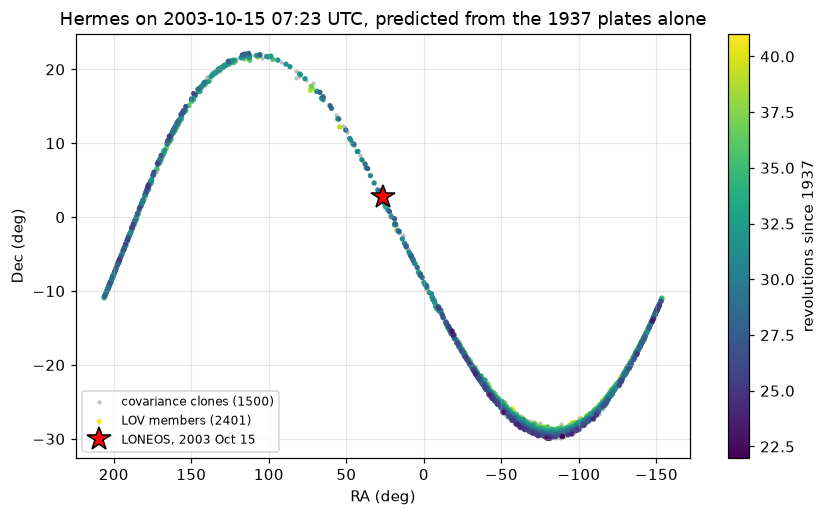

In [9]:
def wrap(ra):            # RA centred on the recovery position, so the plot does not split there
    return (ra - REC["ra_deg"] + 180) % 360 - 180 + REC["ra_deg"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(wrap(ra_c), dec_c, s=3, c="0.75", label="covariance clones (1500)")
sc = ax.scatter(wrap(ra_l), dec_l, s=6, c=np.round(n_rev), cmap="viridis", label=f"LOV members ({N_LOV})")
ax.plot(REC["ra_deg"], REC["dec_deg"], "*", ms=16, mfc="red", mec="k", label="LONEOS, 2003 Oct 15")
fig.colorbar(sc, ax=ax, label="revolutions since 1937")
ax.invert_xaxis()
ax.set(xlabel="RA (deg)", ylabel="Dec (deg)",
       title="Hermes on 2003-10-15 07:23 UTC, predicted from the 1937 plates alone")
ax.legend(fontsize=8, loc="lower left"); plt.show()

The prediction is not a patch of sky but a **track**: Hermes's orbit as seen from Earth, covered
several times over by orbits that differ by whole revolutions. The covariance clones (grey) fill
the same track as the LOV, since in this problem the spread along the orbit dominates everything
else. The true position does lie on the track.

### Where along the LOV, and which revolution?

To know the right answer we need the true orbit, so we borrow the fit to *all* the data (the 1937
plates at 30" and everything since 2000; section 5 looks at it closely) and count the revolutions
it makes between the same two instants.

Then we group the LOV members by the number of whole revolutions they make. Within a group,
moving along the LOV slides the 2003 position along the orbit's track, so every group crosses the
track somewhere near the true position. What tells the groups apart is how far each crossing is
from it. We find the closest point of each group's path (interpolating between consecutive
members) and its LOV coordinate. Because the members are equally probable, the fraction of
members in a group is the probability, from the 1937 data alone, that Hermes made that many
revolutions.

In [10]:
t0 = time.time()
fit_all = pyroorb.fit_orbit(pyroorb.Observations(
    [dict(o, sigma_ra=SIGMA_1937, sigma_dec=SIGMA_1937) if o["jd_utc"] < J1940 else o for o in obs],
    obs.meta), designation="69230")
true_path = pyroorb.propagate(fit_all, Time(grid, format="jd", scale="tdb"))
true_lon = np.unwrap(np.arctan2(true_path[:, 1], true_path[:, 0]))
n_rev_true = (true_lon[-1] - true_lon[0]) / (2 * np.pi)
print(f"all-data fit ({time.time() - t0:.0f} s): the real Hermes made {n_rev_true:.2f} revolutions "
      f"between 1937-10-25 and the recovery")

def tangent(ra, dec):      # gnomonic projection about the true position, degrees
    a0, d0 = np.radians(REC["ra_deg"]), np.radians(REC["dec_deg"])
    a, d = np.radians(ra), np.radians(dec)
    c = np.sin(d0) * np.sin(d) + np.cos(d0) * np.cos(d) * np.cos(a - a0)
    return (np.degrees(np.cos(d) * np.sin(a - a0) / c),
            np.degrees((np.cos(d0) * np.sin(d) - np.sin(d0) * np.cos(d) * np.cos(a - a0)) / c), c)

x, y, cosc = tangent(ra_l, dec_l)
group_of = np.floor(n_rev + 0.5).astype(int)
groups, crossing = [], {}
for N in range(group_of.min(), group_of.max() + 1):
    m = np.flatnonzero(group_of == N)
    if not len(m):
        continue
    best_d, best_k, best_i = d_lov[m].min(), k_lov[m[np.argmin(d_lov[m])]], m[np.argmin(d_lov[m])]
    for i, j in zip(m[:-1], m[1:]):               # segments between consecutive members
        if j != i + 1 or cosc[i] < 0.5 or cosc[j] < 0.5:
            continue
        p, q = np.array([x[i], y[i]]), np.array([x[j], y[j]])
        t = np.clip(-p @ (q - p) / max((q - p) @ (q - p), 1e-12), 0, 1)
        dist = np.hypot(*(p + t * (q - p)))
        if dist < best_d:
            best_d, best_k, best_i = dist, k_lov[i] + t * (k_lov[j] - k_lov[i]), (i if t < 0.5 else j)
    crossing[N] = best_i
    groups.append({"revolutions": N, "probability (%)": round(100 * len(m) / len(n_rev), 1),
                   "LOV range (σ)": f"{k_lov[m].min():+.2f} … {k_lov[m].max():+.2f}",
                   "closest crossing at (σ)": round(best_k, 3),
                   "miss distance (deg)": round(best_d, 2)})
g = pd.DataFrame(groups).set_index("revolutions")
N_true = int(np.floor(n_rev_true + 0.5))
best = crossing[N_true]                      # the LOV member that best reproduces the real 2003 position
print(f"true group: {N_true} revolutions, prior probability {g.loc[N_true, 'probability (%)']} %, "
      f"crossing at {g.loc[N_true, 'closest crossing at (σ)']:+.2f} σ, "
      f"{g.loc[N_true, 'miss distance (deg)']:.2f} deg from the LONEOS position")
g

all-data fit (56 s): the real Hermes made 30.95 revolutions between 1937-10-25 and the recovery
true group: 31 revolutions, prior probability 14.7 %, crossing at +0.11 σ, 0.42 deg from the LONEOS position


,probability (%),LOV range (σ),closest crossing at (σ),miss distance (deg)
revolutions,,,,
22,0.0,+3.00 … +3.00,3.000,113.62
23,0.2,+2.46 … +2.74,2.464,47.75
24,0.4,+2.13 … +2.41,2.178,48.61
25,1.0,+1.83 … +2.15,1.889,0.59
26,1.8,+1.54 … +1.82,1.596,38.31
27,3.5,+1.17 … +1.55,1.309,8.05
28,6.4,+0.92 … +1.30,0.992,0.23
29,9.0,+0.48 … +0.97,0.698,0.23
30,11.2,+0.34 … +0.67,0.340,40.17


The real Hermes made 30.95 revolutions, the "almost exactly 31" of MPEC 2003-T74. From the
1937 plates alone, 31 is the single most probable count, but at only 15 %. Counts from 26 to 37
each have more than 1 %. Within the 31-revolution group, the path crosses the true position
0.4° away, at +0.11σ along the LOV.

That crossing is close, but so are several others. The 25-, 28-, 29-, 32- and 38-revolution groups
also pass within 1° of where LONEOS found Hermes. (Distances come from straight-line
interpolation between members about a degree apart, so they are good to a few tenths of a
degree.) A single position in 2003 therefore cannot say how many times Hermes went round. It
took the 2003 orbit, fitted to observations from August to October, to make the identification.
Section 4 shows that the +0.11σ crossing is not the real Hermes either.

### How large a search?

Suppose the 1937 orbit were the only information and an observer could photograph a 100-square-
degree field on 15 October 2003 (about 10° × 10°, a night of a 1990s-era photographic or CCD
search). We centre a 5.64°-radius circle (100 deg²) on each covariance clone in turn, keep the
best one, and ask what fraction of clones it contains. The search also has to be deep enough. We
compute each clone's V magnitude from JPL's H = 17.68 (G = 0.15) and count only those brighter
than V = 19.5, roughly a 2003 survey's limit.

In [11]:
H, G = 17.68, 0.15                                   # JPL SBDB H; standard G
earth = pyroorb.body_states("earth", [REC["jd_utc"]])[0, :3]
def vmag(ra, dec, delta):
    u = np.stack([np.cos(np.radians(dec)) * np.cos(np.radians(ra)),
                  np.cos(np.radians(dec)) * np.sin(np.radians(ra)), np.sin(np.radians(dec))], -1)
    helio = earth + delta[:, None] * u               # heliocentric position (topocentre ~ geocentre)
    r, R = np.linalg.norm(helio, axis=1), np.linalg.norm(earth)
    alpha = np.arccos(np.clip((r**2 + delta**2 - R**2) / (2 * r * delta), -1, 1))
    phi1 = np.exp(-3.33 * np.tan(alpha / 2) ** 0.63); phi2 = np.exp(-1.87 * np.tan(alpha / 2) ** 1.22)
    return H + 5 * np.log10(r * delta) - 2.5 * np.log10((1 - G) * phi1 + G * phi2)

v_c = vmag(ra_c, dec_c, dlt_c)
v_true = vmag(np.array([REC["ra_deg"]]), np.array([REC["dec_deg"]]),
              np.array([pyroorb.ephemeris(fit37, REC["jd_utc"], REC["jd_utc"], site="699",
                                          full=False)[0]["delta_au"]]))
bright = v_c < 19.5
radius = np.degrees(np.arccos(1 - 100 / (2 * np.pi * np.degrees(1) ** 2)))   # 100 deg² cap
best_frac = max(np.mean(sep_deg(ra_c, dec_c, ra_c[i], dec_c[i]) < radius) for i in range(len(ra_c)))
best_frac_b = max(np.mean(bright & (sep_deg(ra_c, dec_c, ra_c[i], dec_c[i]) < radius))
                  for i in range(len(ra_c)))
print(f"clones brighter than V = 19.5 that night: {bright.mean():.0%} "
      f"(geocentric distance of those: {dlt_c[bright].min():.2f}-{dlt_c[bright].max():.2f} au)")
print(f"best single 100 deg² field: contains {best_frac:.1%} of all clones, "
      f"{best_frac_b:.1%} that are also brighter than V = 19.5")
print(f"clones within 5.64 deg of the true position: {np.mean(d_cov < radius):.1%}")

clones brighter than V = 19.5 that night: 19% (geocentric distance of those: 0.15-1.94 au)
best single 100 deg² field: contains 13.2% of all clones, 2.6% that are also brighter than V = 19.5
clones within 5.64 deg of the true position: 0.5%


The best 100-deg² field holds 13 % of the clones, but most of those are far away and faint: only
2.6 % of the clones are both inside it and brighter than V = 19.5. The 100 deg² around the true
position hold 0.5 % of the clones. Only about one clone in five is bright enough to see at all
that night, and those are spread along the whole visible track. Covering the 1937 prediction
means imaging the whole track, night after night, and that is what an all-sky survey does
anyway. That is how Hermes was found.

## 4. What happened between 1937 and 2003

The LOV says the period was uncertain. The planets also changed it. The cell below lists Hermes's
Earth encounters within 0.06 au from 1937 to 2003, computed on the all-data orbit `fit_all`,
next to JPL's close-approach table.

In [12]:
cas = pyroorb.close_approaches(fit_all, "1937-10-01", "2003-12-31", max_distance=0.06)
try:
    url = ("https://ssd-api.jpl.nasa.gov/cad.api?des=69230&date-min=1937-01-01"
           "&date-max=2003-12-31&dist-max=0.06")
    cad = json.load(urllib.request.urlopen(url, timeout=30))
    jcad = [dict(zip(cad["fields"], r)) for r in cad["data"]]
except Exception as ex:
    print("JPL close-approach API unavailable:", ex); jcad = []
from datetime import datetime
rows = []
for c in cas:
    j = min(jcad, key=lambda r: abs(Time(datetime.strptime(r["cd"], "%Y-%b-%d %H:%M")).jd
                                    - c["jd_tdb"]), default=None)
    rows.append({"PyRoOrb (UTC)": c["date_iso"][:16], "distance (au)": round(c["distance_au"], 5),
                 "JPL (TDB)": j["cd"] if j else None,
                 "JPL distance (au)": round(float(j["dist"]), 5) if j else None})
pd.DataFrame(rows)

,PyRoOrb (UTC),distance (au),JPL (TDB),JPL distance (au)
0,1937-10-30 17:05,0.00495,1937-Oct-30 17:06,0.00495
1,1942-04-26 18:18,0.00424,1942-Apr-26 18:19,0.00424
2,1954-11-01 21:15,0.02044,1954-Nov-01 21:16,0.02044
3,1974-04-24 15:08,0.03511,1974-Apr-24 15:09,0.03511
4,1986-10-29 00:39,0.05332,1986-Oct-29 00:40,0.05332
5,2003-11-04 04:47,0.04784,2003-Nov-04 04:49,0.04784


Hermes passes Earth at a 12-to-20-year rhythm: it came even closer in **April 1942 (0.004 au)**
than at its discovery, again at 0.02 au in 1954, and more distantly in 1974, 1986 and 2003.
PyRoOrb's dates and distances agree with JPL's to the minute and to 10⁻⁵ au.

### Where on the LOV is the real Hermes?

A 1942 pass at 0.004 au needs the right timing: Hermes and Earth must arrive at the crossing point
within a few hours of each other. Orbits elsewhere on the 1937 LOV have slightly different periods,
so they arrive days early or late and pass far from Earth. `OrbitEnsemble.close_approaches`
measures every LOV member's closest approach in 1942. We also place the real orbit on the LOV:
we compute its osculating *a* at the 1937 epoch and find the LOV coordinate with the same *a*.

1942 scan of 2401 LOV members: 68 s
real orbit at the 1937 epoch: a = 1.6350 au (JPL 1.6350) -> LOV coordinate +0.016 σ
members passing within 0.01 au of Earth in 1942: LOV +0.012 … +0.018 σ (0.3% of the probability); they make 30.81-31.84 revolutions by 2003
the member whose 1942 pass is closest to the real 0.0042 au: LOV +0.016 σ, 1942 miss 0.0047 au, 30.93 revolutions, 33.79 deg from the LONEOS position in 2003


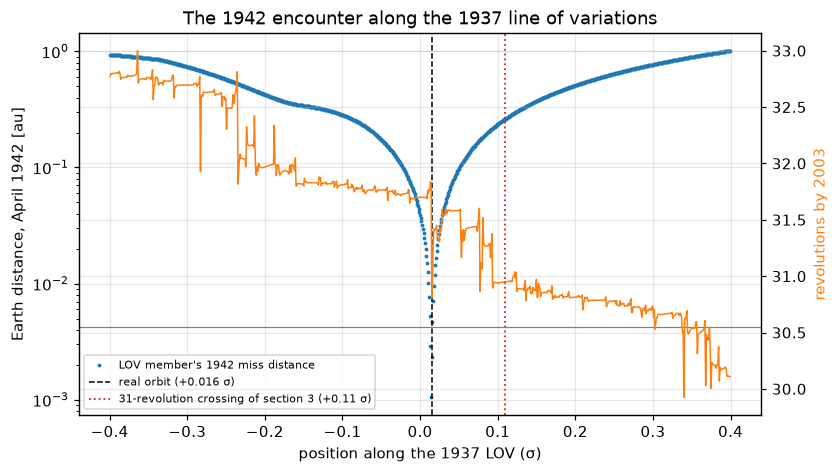

In [13]:
t0 = time.time()
ca42 = ens_lov.close_approaches("1942-01-01", "1943-01-01", max_distance=0.3, half_window=60)[0]
miss42 = np.asarray(ca42["distance_au"])
mu = 0.01720209895 ** 2                       # Sun's GM, au^3/day^2
def semimajor(states):
    r = np.linalg.norm(states[..., :3], axis=-1); v2 = np.sum(states[..., 3:] ** 2, axis=-1)
    return 1 / (2 / r - v2 / mu)
a_epoch = semimajor(ens_lov.states)                                  # LOV members at the 1937 epoch
a_true_1937 = semimajor(pyroorb.propagate(fit_all, Time(fit37.epoch_jd(), format="jd", scale="tdb"))[0])
order = np.argsort(a_epoch)
k_true = float(np.interp(a_true_1937, a_epoch[order], k_lov[order]))
print(f"1942 scan of {len(miss42)} LOV members: {time.time() - t0:.0f} s")
print(f"real orbit at the 1937 epoch: a = {a_true_1937:.4f} au (JPL 1.6350) -> LOV coordinate {k_true:+.3f} σ")
deep = np.flatnonzero(miss42 < 0.01)
print(f"members passing within 0.01 au of Earth in 1942: LOV {k_lov[deep].min():+.3f} … {k_lov[deep].max():+.3f} σ "
      f"({len(deep) / len(k_lov):.1%} of the probability); they make "
      f"{n_rev[deep].min():.2f}-{n_rev[deep].max():.2f} revolutions by 2003")
i_real = deep[np.argmin(np.abs(miss42[deep] - cas[1]["distance_au"]))]   # a member with the real 1942 pass
print(f"the member whose 1942 pass is closest to the real {cas[1]['distance_au']:.4f} au: LOV {k_lov[i_real]:+.3f} σ, "
      f"1942 miss {miss42[i_real]:.4f} au, {n_rev[i_real]:.2f} revolutions, "
      f"{d_lov[i_real]:.2f} deg from the LONEOS position in 2003")

fig, ax = plt.subplots()
sel = np.abs(k_lov) < 0.4
ax.semilogy(k_lov[sel], miss42[sel], ".", ms=3, c="C0", label="LOV member's 1942 miss distance")
ax.axvline(k_true, c="k", ls="--", lw=1, label=f"real orbit ({k_true:+.3f} σ)")
ax.axvline(k_lov[best], c="C3", ls=":", lw=1.2, label=f"31-revolution crossing of section 3 ({k_lov[best]:+.2f} σ)")
ax.axhline(cas[1]["distance_au"], c="grey", lw=0.8)
ax2 = ax.twinx(); ax2.plot(k_lov[sel], n_rev[sel], c="C1", lw=1); ax2.set_ylabel("revolutions by 2003", color="C1")
ax.set(xlabel="position along the 1937 LOV (σ)", ylabel="Earth distance, April 1942 [au]",
       title="The 1942 encounter along the 1937 line of variations")
ax.legend(fontsize=7, loc="lower left"); plt.show()

The 1942 encounter is a narrow **keyhole** on the 1937 LOV. Only members between +0.012σ and
+0.018σ (0.3 % of the probability) pass within 0.01 au of Earth. The nominal 1937 orbit misses
by 0.04 au, and the +0.11σ member that crossed the 2003 position misses by about 0.26 au. The
real orbit, placed on the LOV by its 1937 semimajor axis (1.6350 au, exactly JPL's value), sits
at +0.016σ, inside the keyhole. Orbits that go through it are pushed to a longer period, and the
revolution count (orange) drops by about one across it.

So the real Hermes took a path through the keyhole. The +0.11σ orbit reaches the same spot in
2003 by another route. Even inside the keyhole the outcome is fragile. The member whose 1942
pass is closest to the real one (0.0047 au against 0.0042 au) also makes 31 revolutions, yet it
ends up 34° from the LONEOS position.

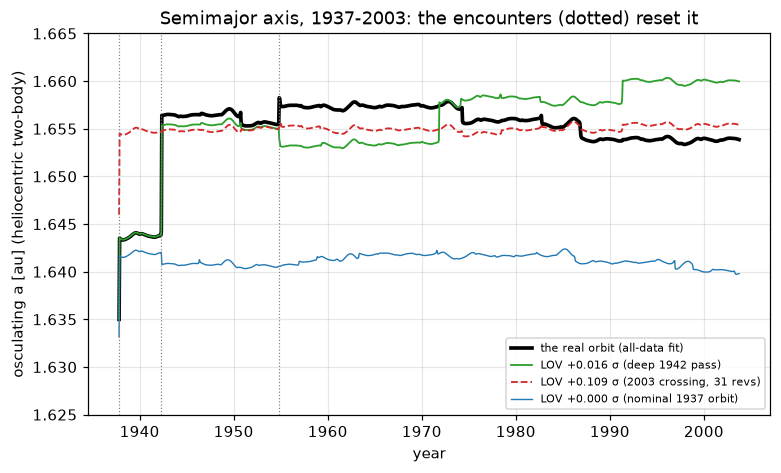

           real orbit  deep-1942 member  2003-crossing member  nominal
1937 pass      0.0084            0.0084                0.0085   0.0084
1942 pass      0.0127            0.0116                0.0002  -0.0011
1954 pass      0.0019           -0.0019                0.0002   0.0002 
(change of osculating a across each encounter, au)


In [14]:
a_t, a_true = semimajor(path), semimajor(true_path)
yr = Time(grid, format="jd", scale="tdb").decimalyear
fig, ax = plt.subplots()
ax.plot(yr, a_true, c="k", lw=2.4, label="the real orbit (all-data fit)")
ax.plot(yr, a_t[:, i_real], c="C2", lw=1.2, label=f"LOV {k_lov[i_real]:+.3f} σ (deep 1942 pass)")
ax.plot(yr, a_t[:, best], c="C3", lw=1.2, ls="--", label=f"LOV {k_lov[best]:+.3f} σ (2003 crossing, 31 revs)")
j0 = int(np.argmin(np.abs(k_lov)))
ax.plot(yr, a_t[:, j0], c="C0", lw=0.9, label=f"LOV {k_lov[j0]:+.3f} σ (nominal 1937 orbit)")
for c in cas:
    if c["distance_au"] < 0.03:
        ax.axvline(Time(c["jd_tdb"], format="jd", scale="tdb").decimalyear, ls=":", c="grey", lw=0.8)
ax.set(xlabel="year", ylabel="osculating a [au] (heliocentric two-body)", ylim=(1.625, 1.665),
       title="Semimajor axis, 1937-2003: the encounters (dotted) reset it")
ax.legend(fontsize=7, loc="lower right"); plt.show()
steps = {"1937 pass": (1937.0, 1937.90), "1942 pass": (1942.0, 1942.7), "1954 pass": (1954.5, 1955.2)}
members = {"real orbit": a_true, "deep-1942 member": a_t[:, i_real], "2003-crossing member": a_t[:, best],
           "nominal": a_t[:, j0]}
print(pd.DataFrame({name: {lab: round(a[np.searchsorted(yr, t2)] - a[np.searchsorted(yr, t1)], 4)
                           for lab, (t1, t2) in steps.items()} for name, a in members.items()})
      .to_string(), "\n(change of osculating a across each encounter, au)")

The real orbit (black) picks up +0.009 au at the 1937 pass and +0.013 au in 1942. Those two
encounters set its period for the next 60 years. The keyhole member (green) follows it through
1942, but its kick is 0.001 au smaller. It then diverges at the 1954 pass and again in the
1970s, and every later pass widens the difference. The +0.11σ member (red) gets all its period
change in 1937 and none in 1942. It has a different history and reaches the same sky position.

That answers "which encounters scrambled the prediction". The 1937 pass is shared by every
member, since the plates were taken during it. The **1942 pass at 0.004 au** splits the LOV into
orbits that do and do not go through a keyhole 0.006σ wide. The 1954 pass at 0.02 au and the
weaker ones later add further sensitivity. No search ephemeris built from the 1937 orbit could
have followed this.

## 5. Linking 1937 to today

Section 3 used `fit_all`, the fit to every observation with the 1937 plates at 30". Two questions
remain. Does the link depend on that weighting? And how does the linked orbit compare with JPL's?
First the same fit with the plates at their default 3":

In [15]:
t0 = time.time()
fit_all_default = pyroorb.fit_orbit(obs, designation="69230")
for label, f in (("1937 plates at 3\" (default)", fit_all_default), (f"1937 plates at {SIGMA_1937:.0f}\"", fit_all)):
    kept37 = sum(r["included"] for o, r in zip(obs, f.residuals()) if o["jd_utc"] < J1940)
    oc37 = np.array([np.hypot(r["d_ra_arcsec"], r["d_dec_arcsec"]) for o, r in zip(obs, f.residuals())
                     if o["jd_utc"] < J1940]) / 60
    print(f"{label:28s}: 1937 plates kept {kept37:2d}/16, their O-C {oc37.min():6.1f}-{oc37.max():6.1f} arcmin; "
          f"{f.n_observations()} of {f.n_total_observations()} obs kept; non-grav: {f.nongrav_model} "
          f"{f.nongrav_params or ''}")
print(f"({time.time() - t0:.0f} s)")

1937 plates at 3" (default) : 1937 plates kept  0/16, their O-C   39.1- 180.7 arcmin; 2348 of 2886 obs kept; non-grav: None 
1937 plates at 30"          : 1937 plates kept 15/16, their O-C    0.1-   1.8 arcmin; 2504 of 2886 obs kept; non-grav: yarkovsky {'A2': -1.3778330976479688e-14}
(50 s)


**The weighting of 16 observations out of 2886 decides the link.** With the plates at the
default 3", the fit keeps none of them. The orbit it builds from 2000-2026 misses them by 39 to
181 arcminutes, and it finds no non-gravitational force. With the plates at 30", it keeps 15 of
16 (one Sonneberg position, 109" off, is rejected), every kept plate fits within 2', and the fit
adds a Yarkovsky term on its own. We did not trace which step of the fit makes the difference.
It is enough to know that this link is fragile, and that the weights given to old astrometry
matter as much as the astrometry itself.

The linked orbit compared with JPL's:

In [16]:
f = fit_all
A2, (A2_lo, A2_hi) = f.nongrav_params["A2"], f.rational_nongrav_intervals()["A2"]
print(f"PyRoOrb A2 = ({A2 * 1e14:.3f} -{A2_lo * 1e14:.3f} +{A2_hi * 1e14:.3f}) x 1e-14 au/d^2")
try:
    sb = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?sstr=69230", timeout=30))
    jA2 = next(p for p in sb["orbit"]["model_pars"] if p["name"] == "A2")
    jA2v, jA2s = float(jA2["value"]), float(jA2["sigma"])
    print(f"JPL     A2 = ({jA2v * 1e14:.3f} ± {jA2s * 1e14:.3f}) x 1e-14 au/d^2  "
          f"(solution {sb['orbit']['orbit_id']}, {sb['orbit']['comment']})")
    print(f"difference: {(A2 - jA2v) / jA2s:+.1f} JPL σ")
except Exception as ex:
    print("SBDB unavailable:", ex)
print(f"H = {f.absolute_magnitude()[0]:.2f} (JPL 17.68); rms {f.rms_residual():.2f}\" "
      f"(normalised {f.rms_normalized():.2f}), arc {f.arc_length_days() / 365.25:.0f} years")
try:
    row = horizons({"EPHEM_TYPE": "ELEMENTS", "CENTER": "'500@10'", "REF_PLANE": "ECLIPTIC",
                    "TLIST": f"'{f.epoch_jd()}'", "TIME_TYPE": "TDB", "OUT_UNITS": "AU-D",
                    "CSV_FORMAT": "YES"}).split("$$SOE")[1].split("$$EOE")[0].split(",")
    jpl = dict(zip(["e", "q", "i", "asc_node", "arg_per"], map(float, row[2:7])))
    jpl["a"] = float(row[11])
    print(f"osculating elements at {f.epoch_iso()[:10]} (TDB):")
    for k in ("a", "e", "q", "i", "asc_node", "arg_per"):
        v, s = f.elements()[k], f.element_sigmas()[k]
        print(f"  {k:8s} PyRoOrb {v:.8f} ± {s:.1e}   JPL {jpl[k]:.8f}   "
              f"diff {v - jpl[k]:+.1e} ({(v - jpl[k]) / s:+.0f} formal σ)")
except Exception as ex:
    print("Horizons unavailable:", ex)

PyRoOrb A2 = (-1.378 -0.017 +0.017) x 1e-14 au/d^2


JPL     A2 = (-1.245 ± 0.171) x 1e-14 au/d^2  (solution 205, Nongravitational accels. using nonstandard g(r) = (1 au/ r)^2)
difference: -0.8 JPL σ
H = 17.58 (JPL 17.68); rms 2.08" (normalised 0.93), arc 89 years


osculating elements at 2022-08-03 (TDB):
  a        PyRoOrb 1.65545732 ± 2.4e-10   JPL 1.65545733   diff -8.3e-10 (-3 formal σ)
  e        PyRoOrb 0.62380190 ± 5.9e-10   JPL 0.62380191   diff -1.0e-08 (-17 formal σ)
  q        PyRoOrb 0.62277990 ± 1.0e-09   JPL 0.62277989   diff +1.6e-08 (+16 formal σ)
  i        PyRoOrb 6.06704388 ± 1.2e-07   JPL 6.06703080   diff +1.3e-05 (+105 formal σ)
  asc_node PyRoOrb 34.06763476 ± 2.1e-06   JPL 34.06769310   diff -5.8e-05 (-28 formal σ)
  arg_per  PyRoOrb 92.90625829 ± 2.1e-06   JPL 92.90620098   diff +5.7e-05 (+28 formal σ)


* **Yarkovsky drift**: PyRoOrb finds A2 = −1.38 × 10⁻¹⁴ au/day², JPL −1.25 ± 0.17 × 10⁻¹⁴, a
  difference of 0.8 of JPL's σ. Both use the 1/r² law. PyRoOrb's own interval (±0.017) is ten
  times narrower than JPL's quoted σ. It is a formal profile interval with the plates at 30";
  JPL's weighting of the 1937 data, which drives this number, is not public in the SBDB summary,
  so the two σ are not comparable.
* **Elements** at the fit's 2022 epoch agree to about 10⁻⁸ in *a*, *e* and *q*, and to
  6 × 10⁻⁵ ° (0.2") in the angles. The formal σ of an 89-year arc with 2500 observations are
  smaller still, so the differences are 3-105 "formal σ". That is the size you get from
  different weighting, outlier rejection and force models: this fit uses the planets, GR and
  Yarkovsky, while JPL also includes the 16 largest asteroids.
* **H** = 17.58 against JPL's 17.68.

Last, the 1937 plates against the two linked orbits. PyRoOrb's residuals come from the fit;
JPL's are each plate's position minus a Horizons ephemeris for that station and instant. The
same query reproduces the 2003 LONEOS recovery position to 0.1", so it is not the source of the
1937 offsets.

In [17]:
rows = []
for o, r in zip(obs, fit_all.residuals()):
    if o["jd_utc"] >= J1940:
        continue
    jr = {}
    try:
        row = horizons({"EPHEM_TYPE": "OBSERVER", "CENTER": f"'{o['obscode']}@399'",
                        "TLIST": f"'{o['jd_utc']}'", "QUANTITIES": "'1'", "ANG_FORMAT": "DEG",
                        "CSV_FORMAT": "YES", "EXTRA_PREC": "YES"}).split("$$SOE")[1].split("$$EOE")[0].split(",")
        ra, dec = float(row[3]), float(row[4])
        jr = {"O-C JPL RA": (o["ra_deg"] - ra) * 3600 * np.cos(np.radians(dec)),
              "O-C JPL Dec": (o["dec_deg"] - dec) * 3600}
    except Exception:
        pass
    rows.append({"UTC": Time(o["jd_utc"], format="jd").iso[:16], "station": o["obscode"],
                 "O-C PyRoOrb RA": r["d_ra_arcsec"], "O-C PyRoOrb Dec": r["d_dec_arcsec"],
                 "used": r["included"], **jr})
oc = pd.DataFrame(rows).set_index("UTC").round(1)
try:                                                   # the same query, on the 2003 recovery position
    row = horizons({"EPHEM_TYPE": "OBSERVER", "CENTER": "'699@399'", "TLIST": f"'{REC['jd_utc']}'",
                    "QUANTITIES": "'1'", "ANG_FORMAT": "DEG", "CSV_FORMAT": "YES",
                    "EXTRA_PREC": "YES"}).split("$$SOE")[1].split("$$EOE")[0].split(",")
    print(f"check, 2003-10-15 LONEOS position minus Horizons: "
          f"RA {(REC['ra_deg'] - float(row[3])) * 3600 * np.cos(np.radians(REC['dec_deg'])):+.2f}\", "
          f"Dec {(REC['dec_deg'] - float(row[4])) * 3600:+.2f}\"")
except Exception as ex:
    print("Horizons unavailable:", ex)
print("1937 residuals in arcsec (RA times cos Dec)")
oc

check, 2003-10-15 LONEOS position minus Horizons: RA +0.09", Dec +0.05"
1937 residuals in arcsec (RA times cos Dec)


,station,O-C PyRoOrb RA,O-C PyRoOrb Dec,used,O-C JPL RA,O-C JPL Dec
UTC,,,,,,
1937-10-25 05:14,801,5.1,1.7,True,49.9,17.7
1937-10-26 22:03,031,-9.6,-17.7,True,52.9,6.5
1937-10-26 22:36,031,28.6,-18.0,True,91.4,6.3
1937-10-27 21:11,078,2.7,3.1,True,82.7,36.9
1937-10-27 21:26,078,7.4,1.6,True,87.6,35.5
1937-10-27 21:41,078,13.2,0.0,True,93.6,34.1
1937-10-27 21:43,078,5.0,4.5,True,85.4,38.5
1937-10-27 21:58,078,7.2,4.0,True,87.9,38.2
1937-10-27 22:13,078,11.1,2.2,True,92.0,36.6


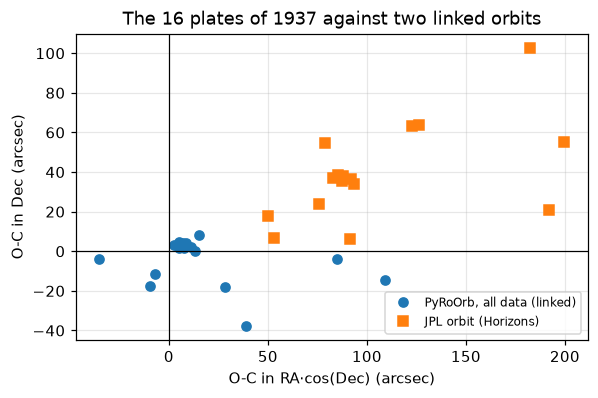

In [18]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(oc["O-C PyRoOrb RA"], oc["O-C PyRoOrb Dec"], "o", label="PyRoOrb, all data (linked)")
if "O-C JPL RA" in oc:
    ax.plot(oc["O-C JPL RA"], oc["O-C JPL Dec"], "s", label="JPL orbit (Horizons)")
ax.axhline(0, c="k", lw=0.8); ax.axvline(0, c="k", lw=0.8)
ax.set(xlabel="O-C in RA·cos(Dec) (arcsec)", ylabel="O-C in Dec (arcsec)",
       title="The 16 plates of 1937 against two linked orbits")
ax.set_aspect("equal"); ax.legend(fontsize=8); plt.show()

PyRoOrb's linked orbit fits the plates with residuals of tens of arcseconds, about their
scatter. JPL's orbit passes **1-3 arcminutes** from them, all on the same side (north-east),
by more as Hermes neared Earth. Both orbits fit the modern data equally well. In 1937 they differ
by about 10⁻⁵ au (roughly 1500 km) in Hermes's position, which is what this many arcminutes
mean at 0.02-0.06 au. Through the 1937 and 1942 keyholes, a difference that small in 1937 is
invisible in today's elements. What sets it is how much weight each solution gives the 1937
plates. Here they were weighted at their own scatter; JPL evidently gives them less. Neither
choice is "the truth". This is the residual uncertainty of linking a 66-year gap through two
close encounters.

## Takeaways

* **Five days of 1937 plates determine an orbit**, if they are weighted for what they are. With
  the default 3" weights PyRoOrb keeps one night and calls the orbit undetermined. At 30", the
  plates' own scatter, all 16 fit. The range profile pins the distance (0.0582 au against JPL's
  0.0583, thanks to the parallax between stations on three continents), and the elements match
  JPL's orbit at 1937 within 0.3σ.
* **The weak quantity is the period**: 2.09 ± 0.23 years, or about ±3.5 revolutions by 2003.
  The prediction for the recovery night is not an ellipse but the orbit's whole track across the
  sky, covered many times over. The LOV is the tool that shows this structure. Statistical
  ranging finds no family on a multi-night arc, as it should not; the linear, Monte-Carlo and
  LOV σ agree in 1937 and part ways only once the orbit is carried forward.
* **The revolution count was ambiguous.** The real Hermes made 31 revolutions (MPEC 2003-T74:
  "almost exactly 31"), the most probable count from 1937 but at only 15 %. Five other counts
  also bring the 1937 orbit within 1° of where LONEOS found it.
* **The 1942 encounter (0.004 au) was a keyhole**: 0.006σ wide on the 1937 LOV, and the real
  orbit (+0.016σ) went through it. Orbits outside it miss Earth by tenths of an au in 1942 and
  make a different number of revolutions. Encounter dates and distances from PyRoOrb agree with
  JPL's table to the minute and to 10⁻⁵ au.
* **A targeted search would not have worked.** The best single 100-deg² field on the recovery
  night holds 2.6 % of the 1937 prediction in a form bright enough to see. Hermes was found the
  only way the LOV allows: by a survey covering the whole sky, on a night it was bright
  (V ≈ 14.4 at 0.2 au).
* **The link back to 1937 works, but it is fragile.** With the plates at 30" PyRoOrb links all
  89 years, finds a Yarkovsky drift of A2 = −1.38 × 10⁻¹⁴ au/day² (JPL −1.25 ± 0.17), and
  matches JPL's modern elements to 10⁻⁸. With the plates at the default 3" it does not link
  them at all. The linked orbits from PyRoOrb and JPL differ by 1-3' on the 1937 sky, which is
  how much a 66-year link through two keyholes leaves to the weighting.

**Caveats.** The 30" weight is one number for four stations of very different quality
(Sonneberg scatters most). A per-station weighting would change the σ, and the 10"/30"/60"
test in section 2b shows it barely moves the 1937 elements, but the link in section 5 is
sensitive to it. The LOV members and covariance clones are gravity-only (sample_orbits'
LOV does not carry a non-gravitational force), and the 1937 data could not have measured
Yarkovsky. Over 66 years its effect is small next to the keyhole. The search-area estimate uses
covariance clones, which cover the same track as the LOV, and a simple H, G magnitude; the
V = 19.5 limit and the 100-deg² field are round numbers, not any particular program. The 1937
plates were reduced against 1930s star positions and carry no catalogue code, so they receive
no debiasing. All fits here use the planets and GR without the asteroid perturbers.

In [19]:
print(f"notebook run time: {(time.time() - T_START) / 60:.1f} min")

notebook run time: 8.0 min
